# Mini-Projet Séries Temporelles — Partie 1
## Collecte, nettoyage, exploration des données et découpage train / test — AAPL & QQQ

Ce notebook produit le fichier `data_aapl_qqq.csv` (données brutes Yahoo Finance) et `dataset_partie1.csv` (jeu de données préparé), réutilisés par les notebooks des parties 2 et 3.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from statsmodels.tsa.stattools import adfuller, kpss

In [4]:
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

In [5]:
tickers = ["AAPL", "QQQ"]

data = yf.download(
    tickers,
    start="2019-01-01",
    end="2026-10-01",
    auto_adjust=False
)

[*********************100%***********************]  2 of 2 completed


In [6]:
import os
print(os.getcwd())

/content


In [7]:
data.to_csv("/content/data_aapl_qqq.csv")

In [8]:
data.head()

Price       Adj Close                  Close                   High  \
Ticker           AAPL         QQQ       AAPL         QQQ       AAPL   
Date                                                                  
2019-01-02  37.436913  147.724457  39.480000  154.880005  39.712502   
2019-01-03  33.707932  142.898193  35.547501  149.820007  36.430000   
2019-01-04  35.146893  149.012009  37.064999  156.229996  37.137501   
2019-01-07  35.068665  150.786148  36.982498  158.089996  37.207500   
2019-01-08  35.737179  152.150055  37.687500  159.520004  37.955002   

Price                         Low                   Open              \
Ticker             QQQ       AAPL         QQQ       AAPL         QQQ   
Date                                                                   
2019-01-02  155.750000  38.557499  150.880005  38.722500  150.990005   
2019-01-03  153.259995  35.500000  149.490005  35.994999  152.600006   
2019-01-04  157.000000  35.950001  151.740005  36.132500  152.339996   
2019-01-07  158.860001  36.474998  156.110001  37.174999  156.619995   
2019-01-08  160.110001  37.130001  157.199997  37.389999  159.539993   

Price          Volume            
Ticker           AAPL       QQQ  
Date                             
2019-01-02  148158800  58576700  
2019-01-03  365248800  74820200  
2019-01-04  234428400  74709300  
2019-01-07  219111200  52059300  
2019-01-08  164101200  49388700

In [9]:
data.tail()

Price        Adj Close                   Close                    High  \
Ticker            AAPL         QQQ        AAPL         QQQ        AAPL   
Date                                                                     
2026-09-24  335.920013  741.099976  335.920013  741.099976  338.910004   
2026-09-25  341.070007  744.500000  341.070007  744.500000  341.670013   
2026-09-28  338.399994  736.530029  338.399994  736.530029  342.989990   
2026-09-29  329.399994  737.929993  329.399994  737.929993  337.089996   
2026-09-30  333.019989  739.770020  333.019989  739.770020  339.500000   

Price                          Low                    Open              \
Ticker             QQQ        AAPL         QQQ        AAPL         QQQ   
Date                                                                     
2026-09-24  742.659973  334.299988  734.619995  336.720001  735.289978   
2026-09-25  745.919983  334.529999  739.640015  336.040009  742.830017   
2026-09-28  741.419983  338.040009  731.630005  340.369995  740.460022   
2026-09-29  740.580017  328.700012  735.340027  336.970001  740.150024   
2026-09-30  745.099976  330.140015  739.460022  330.799988  740.190002   

Price         Volume            
Ticker          AAPL       QQQ  
Date                            
2026-09-24  24733100  29000900  
2026-09-25  30002500  30283800  
2026-09-28  32820800  41775000  
2026-09-29  38478000  27052300  
2026-09-30  49988600  29820400

In [10]:
prices = data["Adj Close"].copy()
volume = data["Volume"].copy()

In [11]:
prices.head()

Ticker,AAPL,QQQ
Date,,
2019-01-02,37.436913,147.724457
2019-01-03,33.707932,142.898193
2019-01-04,35.146893,149.012009
2019-01-07,35.068665,150.786148
2019-01-08,35.737179,152.150055


## les dimensions

In [12]:
print("Nombre de lignes :", len(prices))
print("Nombre de colonnes :", prices.shape[1])

Nombre de lignes : 1947
Nombre de colonnes : 2


In [13]:
print(prices.index.min())
print(prices.index.max())

2019-01-02 00:00:00
2026-09-30 00:00:00


## Valeur manquante

In [14]:
print(prices.isna().sum())

Ticker
AAPL    0
QQQ     0
dtype: int64


In [15]:
print(volume.isna().sum())

Ticker
AAPL    0
QQQ     0
dtype: int64


In [16]:
print("Nombre de dates dupliquées :", prices.index.duplicated().sum())

Nombre de dates dupliquées : 0


In [17]:
print(prices.index.is_monotonic_increasing)

True


## Visualiser les prix

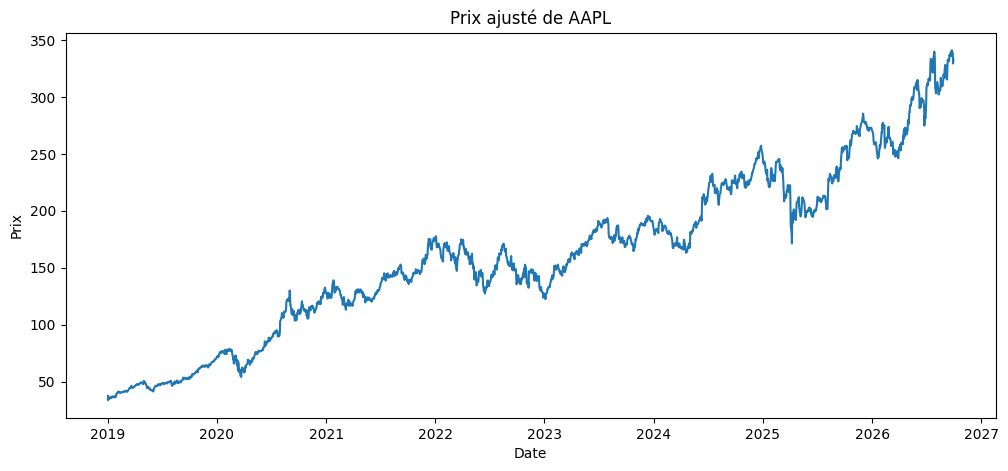

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(prices["AAPL"])
plt.title("Prix ajusté de AAPL")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.show()

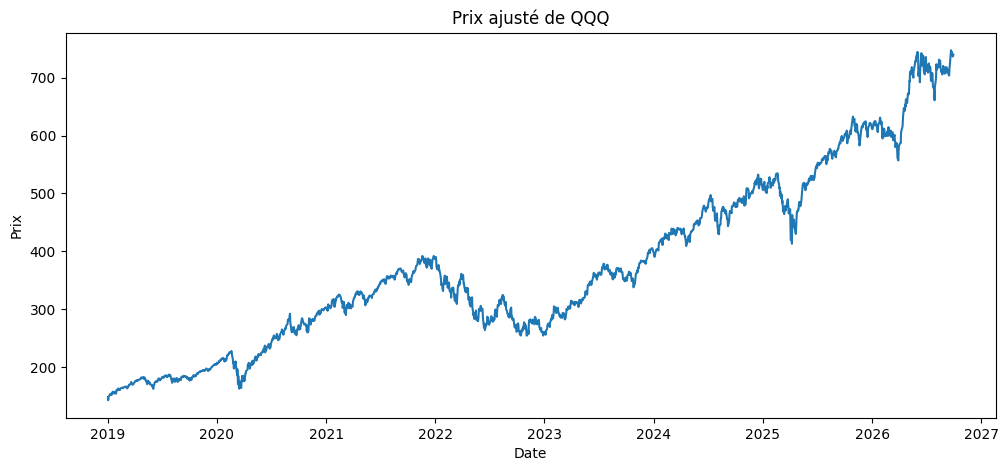

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(prices["QQQ"])
plt.title("Prix ajusté de QQQ")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.show()

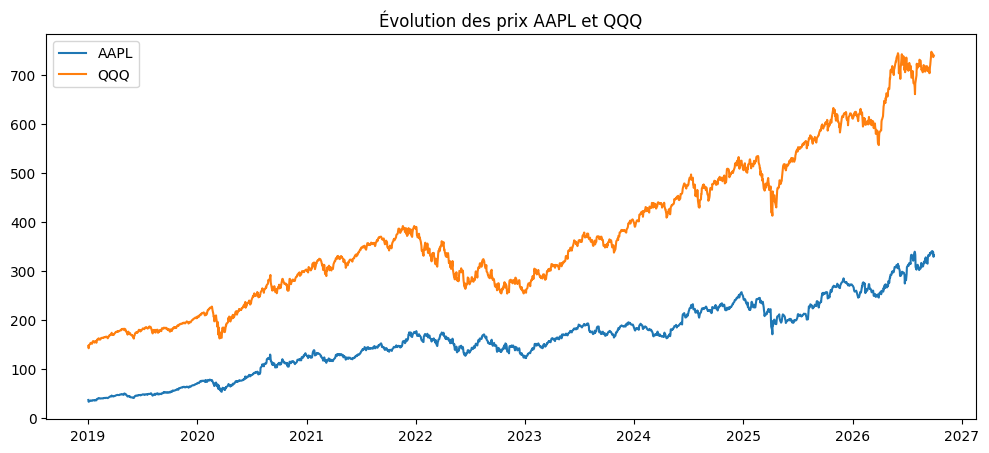

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(prices["AAPL"], label="AAPL")
plt.plot(prices["QQQ"], label="QQQ")
plt.title("Évolution des prix AAPL et QQQ")
plt.legend()
plt.show()

## Créer les rendements logarithmiques
rt​=ln(Pt​/Pt−1​)

In [21]:
returns = np.log(prices / prices.shift(1))

In [22]:
returns = returns.dropna()

In [23]:
returns.head()

Ticker,AAPL,QQQ
Date,,
2019-01-03,-0.104924,-0.033216
2019-01-04,0.041803,0.041894
2019-01-07,-0.002228,0.011836
2019-01-08,0.018884,0.009005
2019-01-09,0.016839,0.008116


## Visualiser les rendements

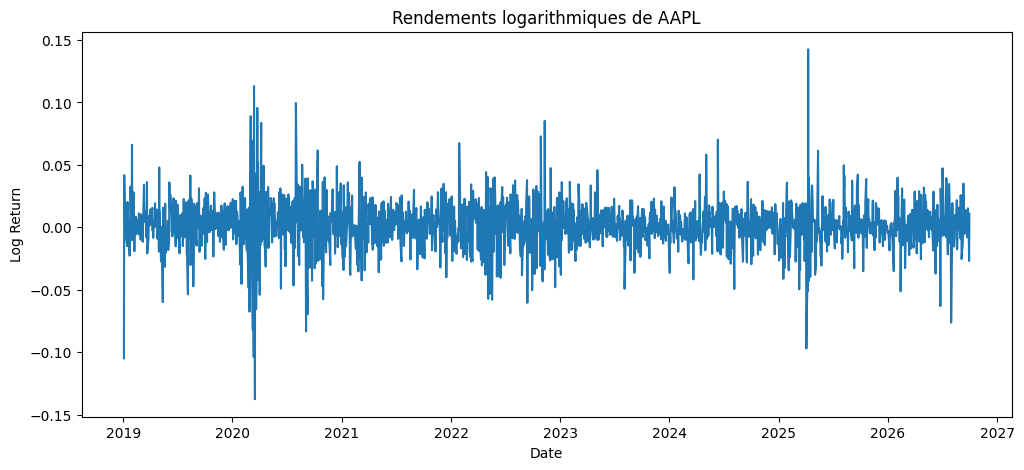

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(returns["AAPL"])
plt.title("Rendements logarithmiques de AAPL")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

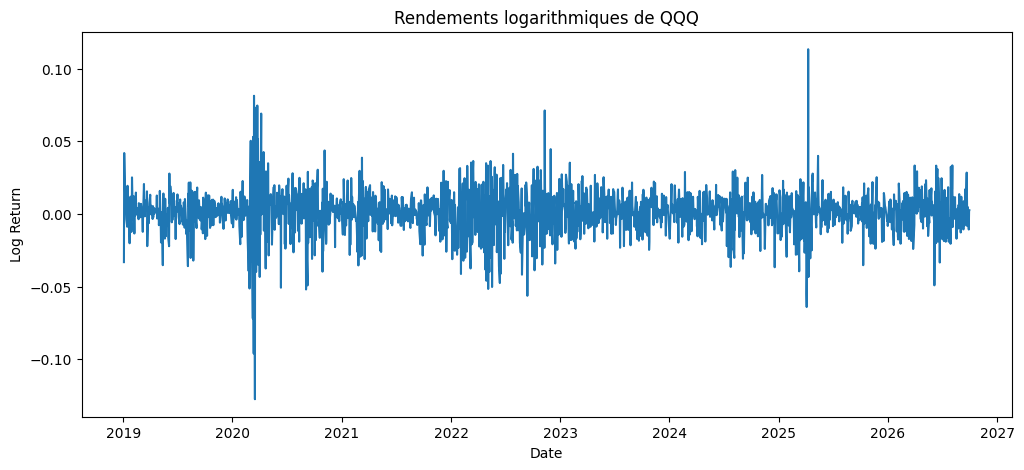

In [25]:
plt.figure(figsize=(12, 5))
plt.plot(returns["QQQ"])
plt.title("Rendements logarithmiques de QQQ")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

## Créer un indicateur technique

In [26]:
prices["AAPL_MA20"] = prices["AAPL"].rolling(20).mean()

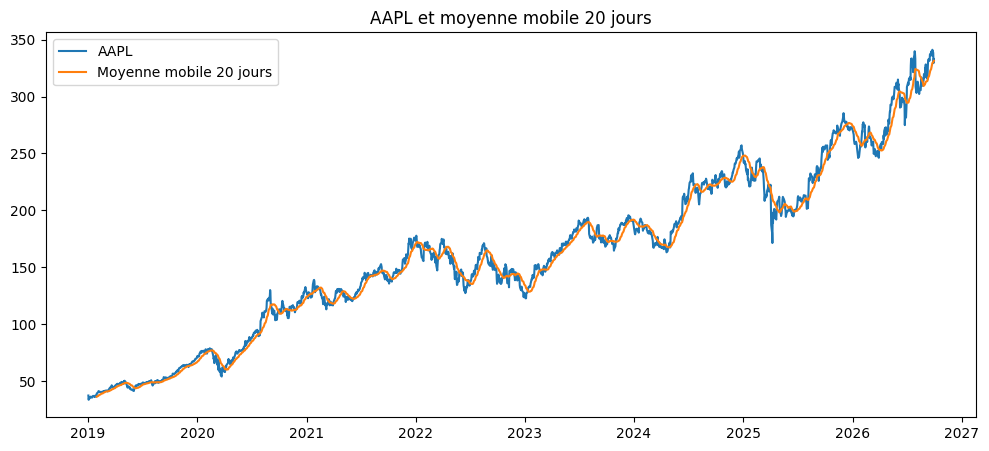

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(prices["AAPL"], label="AAPL")
plt.plot(prices["AAPL_MA20"], label="Moyenne mobile 20 jours")

plt.title("AAPL et moyenne mobile 20 jours")
plt.legend()
plt.show()

## Créer la volatilité réalisée

In [28]:
rolling_volatility = returns["AAPL"].rolling(20).std()

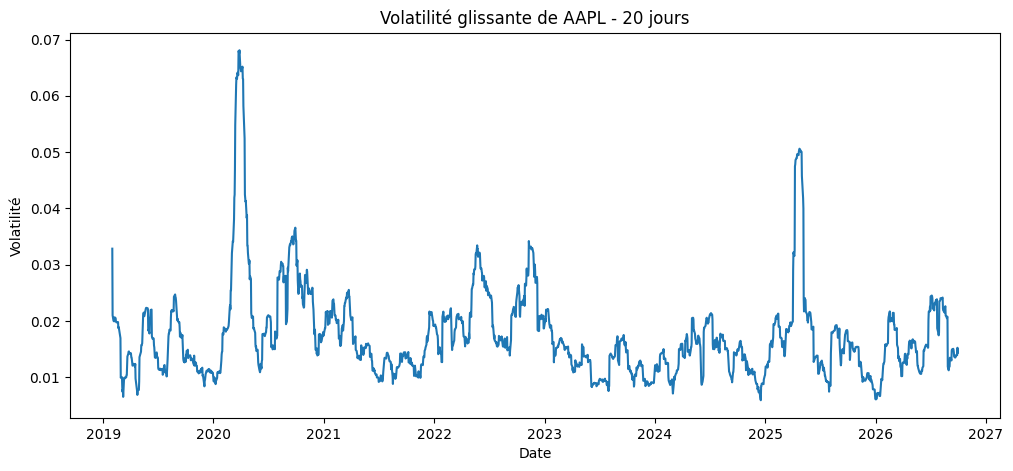

In [29]:
plt.figure(figsize=(12, 5))
plt.plot(rolling_volatility)
plt.title("Volatilité glissante de AAPL - 20 jours")
plt.xlabel("Date")
plt.ylabel("Volatilité")
plt.show()

## Statistiques descriptives

In [30]:
returns["AAPL"].describe()

,AAPL
count,1946.000000
mean,0.001123
std,0.019309
min,-0.137708
25%,-0.007782
50%,0.001301
75%,0.011201
max,0.142618


In [31]:
returns["QQQ"].describe()

,QQQ
count,1946.000000
mean,0.000828
std,0.015073
min,-0.127592
25%,-0.006139
50%,0.001404
75%,0.008745
max,0.113356


In [32]:
print("Skewness AAPL :", returns["AAPL"].skew())
print("Kurtosis AAPL :", returns["AAPL"].kurtosis())

print("Skewness QQQ :", returns["QQQ"].skew())
print("Kurtosis QQQ :", returns["QQQ"].kurtosis())

Skewness AAPL : -0.12014260998729452
Kurtosis AAPL : 6.507927991359658
Skewness QQQ : -0.3657401467158384
Kurtosis QQQ : 7.279879859803641


## Détection des valeurs aberrantes

### Traitement des valeurs aberrantes

Les valeurs extrêmes détectées dans les rendements AAPL et QQQ sont conservées.
Dans le contexte financier, elles peuvent correspondre à de véritables mouvements
du marché et représentent une information importante pour l'analyse de la volatilité.
Une suppression automatique pourrait donc entraîner une perte d'information.

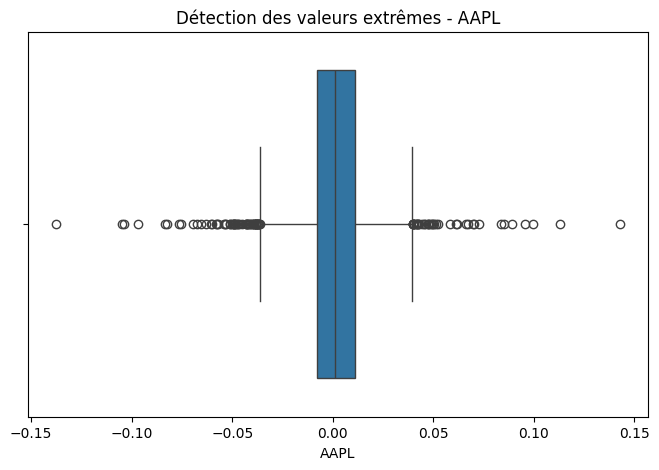

In [33]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=returns["AAPL"])
plt.title("Détection des valeurs extrêmes - AAPL")
plt.show()

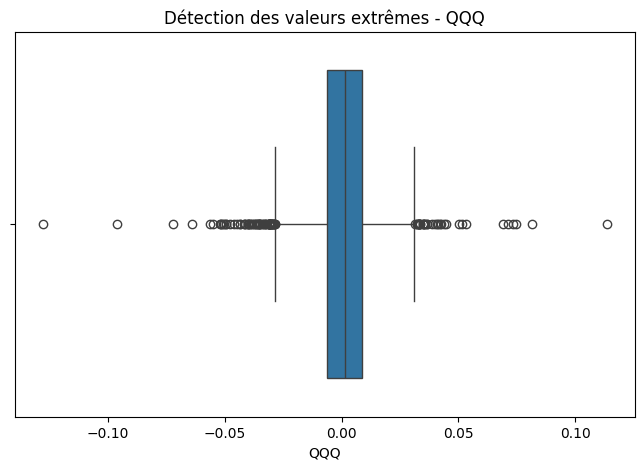

In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=returns["QQQ"])
plt.title("Détection des valeurs extrêmes - QQQ")
plt.show()

In [35]:
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"],
    "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"],
    "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL_MA20"],
    "AAPL_Volatility20": rolling_volatility
})

In [36]:
dataset.head()

,AAPL,QQQ,AAPL_Return,QQQ_Return,AAPL_MA20,AAPL_Volatility20
Date,,,,,,
2019-01-02,37.436913,147.724457,NaN,NaN,NaN,NaN
2019-01-03,33.707932,142.898193,-0.104924,-0.033216,NaN,NaN
2019-01-04,35.146893,149.012009,0.041803,0.041894,NaN,NaN
2019-01-07,35.068665,150.786148,-0.002228,0.011836,NaN,NaN
2019-01-08,35.737179,152.150055,0.018884,0.009005,NaN,NaN


In [37]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1947 entries, 2019-01-02 to 2026-09-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   AAPL               1947 non-null   float64
 1   QQQ                1947 non-null   float64
 2   AAPL_Return        1946 non-null   float64
 3   QQQ_Return         1946 non-null   float64
 4   AAPL_MA20          1928 non-null   float64
 5   AAPL_Volatility20  1927 non-null   float64
dtypes: float64(6)
memory usage: 106.5 KB


In [38]:
split_index = int(len(dataset) * 0.90)

train = dataset.iloc[:split_index].copy()
test = dataset.iloc[split_index:].copy()

In [39]:
print("Train :", len(train))
print("Test :", len(test))

Train : 1752
Test : 195


In [40]:
print("Train jusqu'à :", train.index[-1])
print("Test à partir de :", test.index[0])

Train jusqu'à : 2025-12-18 00:00:00
Test à partir de : 2025-12-19 00:00:00


### Sauvegarde du jeu de données préparé
Les notebooks des parties 2 et 3 repartent de ce fichier (même `dataset`, même découpage 90 % / 10 %).

In [ ]:
dataset.to_csv("dataset_partie1.csv")
print("dataset_partie1.csv écrit :", dataset.shape)